# Yule-Walker Equations

This notebook accompanies the note [Yule-Walker equations](../../notes/time_series/yule_walker_equations.md). For a stationary zero-mean AR($p$) process

$$X_t=\phi_1X_{t-1}+\cdots+\phi_pX_{t-p}+\varepsilon_t,$$

the autocorrelations satisfy $\rho(k)=\sum_{j=1}^{p}\phi_j\rho(k-j)$ for $k\ge1$ and the zero-lag equation $\gamma(0)=\sum_j\phi_j\gamma(j)+\sigma_\varepsilon^2$. We verify the note's calculations and use the equations as an estimator:

1. the AR(2) example $\phi_1=0.6,\ \phi_2=-0.2$ (giving $\rho_1=0.5$, $\rho_2=0.1$, $\rho_3=-0.04$);
2. the matrix form $R\boldsymbol\phi=\mathbf r$;
3. the invalid pair $(3,2)$ versus the stationary pair $(0.3,0.2)$;
4. estimation from data and the innovation variance;
5. conditioning problems at high order.

## 1. AR(2) autocorrelations by recursion

The lag-1 equation $\rho_1=\phi_1+\phi_2\rho_1$ gives $\rho_1=\phi_1/(1-\phi_2)=0.6/1.2=0.5$. Then $\rho_2=\phi_1\rho_1+\phi_2=0.1$, and for later lags $\rho_h=0.6\rho_{h-1}-0.2\rho_{h-2}$, so $\rho_3=0.6(0.1)-0.2(0.5)=-0.04$. We compute the recursion and compare with statsmodels' theoretical ACF.

rho_1 = 0.5   rho_2 = 0.09999999999999998   rho_3 = -0.04
max |recursion - ArmaProcess.acf| = 1.1102230246251565e-16


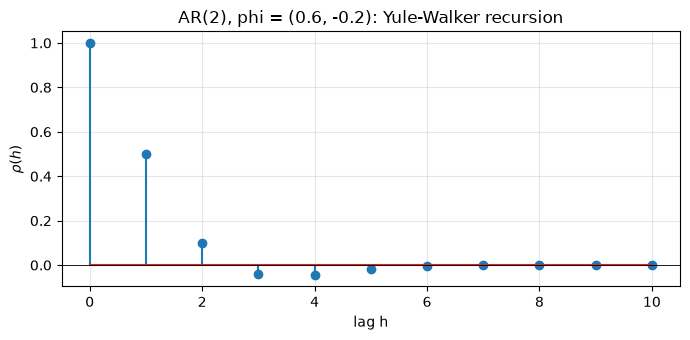

In [1]:
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import solve_toeplitz, toeplitz
from statsmodels.tsa.arima_process import ArmaProcess
from statsmodels.tsa.stattools import acf
from statsmodels.regression.linear_model import yule_walker

phi1, phi2 = 0.6, -0.2
rho = np.zeros(11)
rho[0] = 1.0
rho[1] = phi1 / (1 - phi2)
rho[2] = phi1 * rho[1] + phi2
for h in range(3, 11):
    rho[h] = phi1 * rho[h - 1] + phi2 * rho[h - 2]

print("rho_1 =", rho[1], "  rho_2 =", rho[2], "  rho_3 =", round(rho[3], 4))
theory = ArmaProcess(ar=[1, -phi1, -phi2], ma=[1]).acf(11)
print("max |recursion - ArmaProcess.acf| =", np.abs(rho - theory).max())

plt.figure(figsize=(7, 3.5))
plt.stem(range(11), rho)
plt.axhline(0, color="k", lw=0.6)
plt.xlabel("lag h"); plt.ylabel(r"$\rho(h)$"); plt.title("AR(2), phi = (0.6, -0.2): Yule-Walker recursion")
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

The recursion reproduces $0.5$, $0.1$, $-0.04$ and agrees with the independent statsmodels ACF to machine precision. For this stable model the sequence decays (with a sign change) rather than growing.

## 2. Matrix form: from autocorrelations back to coefficients

With $R=\begin{pmatrix}1&\rho_1\\ \rho_1&1\end{pmatrix}$ and $\mathbf r=(\rho_1,\rho_2)^\top$, solving $R\boldsymbol\phi=\mathbf r$ should return $(0.6,-0.2)$. We also compute the innovation variance. For an AR(1) with $\phi=0.7$, $\gamma(0)=1/(1-0.49)=1.9608$ and $\sigma_\varepsilon^2=\gamma(0)(1-\phi^2)=1$.

In [2]:
R = np.array([[1, rho[1]], [rho[1], 1]])
r = rho[1:3]
phi_hat = np.linalg.solve(R, r)
print("R =\n", R)
print("solved phi:", phi_hat)

# innovation variance: sigma^2 = gamma(0) (1 - sum phi_j rho_j); with sigma^2 = 1 the implied gamma(0) is:
gamma0 = 1.0 / (1 - phi_hat @ r)
print("gamma(0) implied by sigma^2 = 1:", round(gamma0, 4))
print("check via ArmaProcess variance :", round(ArmaProcess(ar=[1, -0.6, 0.2]).acovf(1)[0], 4))

# AR(1) check from the note
phi = 0.7
g0 = 1 / (1 - phi**2)
print("\nAR(1) phi=0.7: gamma(0) =", round(g0, 4), "  sigma^2 =", round(g0 * (1 - phi**2), 4))

R =
 [[1.  0.5]
 [0.5 1. ]]
solved phi: [ 0.6 -0.2]
gamma(0) implied by sigma^2 = 1: 1.3889
check via ArmaProcess variance : 1.3889

AR(1) phi=0.7: gamma(0) = 1.9608   sigma^2 = 1.0


The linear system returns exactly the coefficients we started from, and the zero-lag equation links the variance to the innovation variance in both directions. The two variance computations for the AR(2) agree, and the AR(1) check recovers $\sigma_\varepsilon^2=1$.

## 3. Invalid coefficients $(3,2)$ versus the stationary pair $(0.3,0.2)$

For $X_t=3X_{t-1}+2X_{t-2}+\varepsilon_t$ the formal equations give $\gamma(1)=-3\gamma(0)$, $\gamma(2)=-7\gamma(0)$, i.e. $\rho_1=-3$ and $\rho_2=-7$, impossible since $|\rho|\le1$. The homogeneous recursion has roots $\lambda=(3\pm\sqrt{17})/2\approx3.5616,\,-0.5616$ with constants $c_1\approx-0.59$, $c_2\approx1.59$. For $(0.3,0.2)$: $\rho_1=0.375$, $\rho_2=0.3125$.

rho_1, rho_2 = -3.0 -7.0
lambda: [ 3.5616 -0.5616]   c1, c2 = -0.591 1.591
c1*l1^2 + c2*l2^2 = -7.0 (equals rho_2 = -7)
AR polynomial roots in z: [-1.7808  0.2808]  stationary? False

(0.3,0.2): rho_1=0.3750 rho_2=0.3125  stationary? True  |roots in z|=[3.108 1.608]


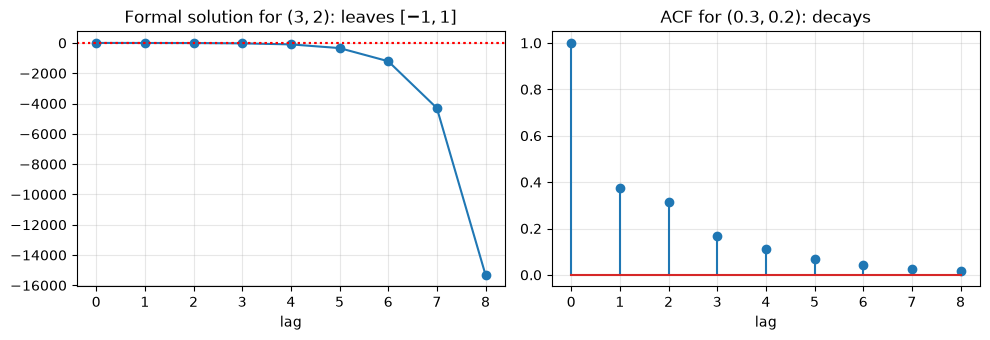

In [3]:
# invalid pair
p1, p2 = 3.0, 2.0
rho1_bad = p1 / (1 - p2)
rho2_bad = p1 * rho1_bad + p2
print("rho_1, rho_2 =", rho1_bad, rho2_bad)

lam = np.roots([1, -p1, -p2])
l1, l2 = lam[0], lam[1]
c1 = (rho1_bad - l2) / (l1 - l2)
c2 = 1 - c1
print("lambda:", np.round(lam, 4), "  c1, c2 =", round(c1, 3), round(c2, 3))
print("c1*l1^2 + c2*l2^2 =", round(c1 * l1**2 + c2 * l2**2, 4), "(equals rho_2 = -7)")

proc_bad = ArmaProcess(ar=[1, -p1, -p2], ma=[1])
print("AR polynomial roots in z:", np.round(proc_bad.arroots, 4), " stationary?", proc_bad.isstationary)

# stationary alternative
a1, a2 = 0.3, 0.2
r1 = a1 / (1 - a2); r2 = a1 * r1 + a2
proc_ok = ArmaProcess(ar=[1, -a1, -a2], ma=[1])
print(f"\n(0.3,0.2): rho_1={r1:.4f} rho_2={r2:.4f}  stationary? {proc_ok.isstationary}  "
      f"|roots in z|={np.round(np.abs(proc_ok.arroots), 3)}")

k = np.arange(0, 9)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(k, c1 * l1**k + c2 * l2**k, "o-"); ax[0].axhline(1, color="r", ls=":"); ax[0].axhline(-1, color="r", ls=":")
ax[0].set_title(r"Formal solution for $(3,2)$: leaves $[-1,1]$")
ax[1].stem(k, proc_ok.acf(9)); ax[1].set_title(r"ACF for $(0.3,0.2)$: decays")
for a in ax: a.grid(alpha=0.3); a.set_xlabel("lag")
plt.tight_layout(); plt.show()

The formal solution for $(3,2)$ blows up past the $[-1,1]$ bounds (the $\lambda_1\approx3.56$ term dominates), and the AR polynomial has a root with modulus below one, so no stationary ACF exists. The stationary pair gives $0.375$ and $0.3125$ and a decaying ACF. Always check that Yule-Walker output is a valid autocorrelation sequence.

## 4. Estimation from data

Replacing $\rho$ by sample autocorrelations $\hat\rho$ gives the Yule-Walker estimator $\hat{\boldsymbol\phi}=\hat R^{-1}\hat{\mathbf r}$ (solved as a Toeplitz system), with $\hat\sigma_\varepsilon^2=\hat\gamma(0)-\sum_j\hat\phi_j\hat\gamma(j)$. We simulate the AR(2) with $\sigma_\varepsilon^2=1$ and compare with statsmodels.

my estimate   : phi = [ 0.6067 -0.2104]  sigma^2 = 1.0044
statsmodels   : phi = [ 0.6067 -0.2104]  sigma^2 = 1.0044
true          : phi = [0.6 -0.2]  sigma^2 = 1
sample rho_1..3: [ 0.5012  0.0937 -0.0653]  theory [ 0.5   0.1  -0.04]
n=250 replicates: mean phi_hat = [ 0.593 -0.211]  sd = [0.062 0.064]


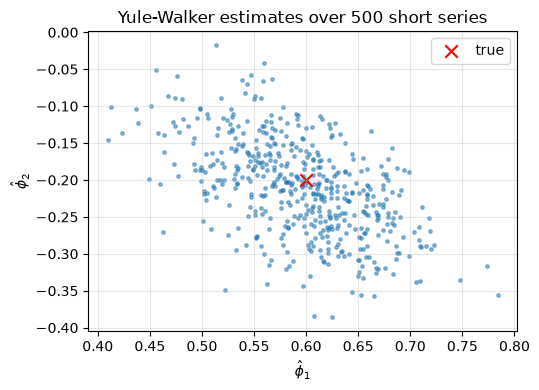

In [4]:
rng = np.random.default_rng(123)
n = 5000
e = rng.normal(0, 1, n + 500)
x = np.zeros(n + 500)
for t in range(2, n + 500):
    x[t] = phi1 * x[t - 1] + phi2 * x[t - 2] + e[t]
x = x[500:]
x = x - x.mean()

def yw_fit(x, p):
    n = len(x)
    g = np.array([np.dot(x[:n - k], x[k:]) / n for k in range(p + 1)])   # sample autocovariances
    phi = solve_toeplitz(g[:p], g[1:p + 1])
    sigma2 = g[0] - phi @ g[1:p + 1]
    return phi, sigma2, g

phi_hat, s2_hat, g = yw_fit(x, 2)
print("my estimate   : phi =", np.round(phi_hat, 4), " sigma^2 =", round(s2_hat, 4))
rho_sm, sig_sm = yule_walker(x, order=2, method="mle", demean=False)
print("statsmodels   : phi =", np.round(rho_sm, 4), " sigma^2 =", round(sig_sm**2, 4))
print("true          : phi = [0.6 -0.2]  sigma^2 = 1")
print("sample rho_1..3:", np.round(acf(x, nlags=3, fft=False)[1:], 4), " theory", np.round(rho[1:4], 4))

# sampling variability over many short series
est = []
for _ in range(500):
    ee = rng.normal(size=250)
    xx = np.zeros(250)
    for t in range(2, 250):
        xx[t] = phi1 * xx[t - 1] + phi2 * xx[t - 2] + ee[t]
    est.append(yw_fit(xx - xx.mean(), 2)[0])
est = np.array(est)
print("n=250 replicates: mean phi_hat =", np.round(est.mean(0), 3), " sd =", np.round(est.std(0), 3))

plt.figure(figsize=(5.5, 4))
plt.scatter(est[:, 0], est[:, 1], s=6, alpha=0.5)
plt.scatter([phi1], [phi2], c="r", marker="x", s=80, label="true")
plt.xlabel(r"$\hat\phi_1$"); plt.ylabel(r"$\hat\phi_2$"); plt.legend(); plt.grid(alpha=0.3)
plt.title("Yule-Walker estimates over 500 short series"); plt.tight_layout(); plt.show()

With a long sample the estimates sit very close to $(0.6,-0.2)$ and $\sigma^2_\varepsilon\approx1$, and the hand-built Toeplitz solve matches statsmodels. In short samples (here $n=250$) the estimates scatter noticeably around the truth, which is the sampling noise the note warns about; a sample ACF will not equal the population values exactly.

## 5. Conditioning at high order and misuse on a random walk

Higher-order Toeplitz systems can be poorly conditioned. We compute the condition number of $R$ for AR(1)-type correlations $\rho(h)=\phi^{|h|}$ of increasing order and strong persistence. Finally, applying Yule-Walker blindly to a random walk returns a coefficient pinned near 1: it is a symptom of non-stationarity, not a valid stationary AR estimate.

phi=0.50: cond(R) for p=2,5,10,20 -> [3.  6.3 7.9 8.6]
phi=0.90: cond(R) for p=2,5,10,20 -> [ 19.   73.4 135.5 212.2]
phi=0.99: cond(R) for p=2,5,10,20 -> [ 199.   885.9 1878.6 3704.7]

Yule-Walker AR(1) on a random walk: phi_hat = [0.9905]


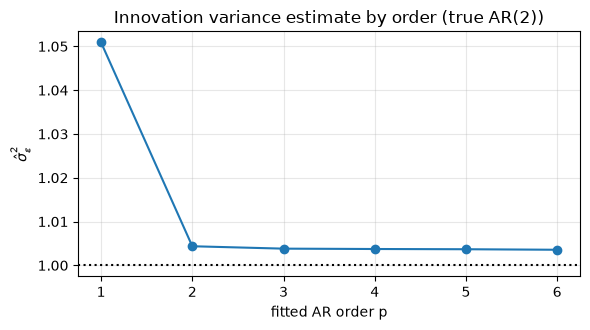

sigma^2 by order: [1.0509 1.0044 1.0038 1.0037 1.0037 1.0036]


In [5]:
for phi_ in (0.5, 0.9, 0.99):
    conds = []
    for p in (2, 5, 10, 20):
        Rp = toeplitz(phi_ ** np.arange(p))
        conds.append(np.linalg.cond(Rp))
    print(f"phi={phi_:4.2f}: cond(R) for p=2,5,10,20 ->", np.round(conds, 1))

rw = np.cumsum(rng.normal(size=1000))
phi_rw, s2_rw, _ = yw_fit(rw - rw.mean(), 1)
print("\nYule-Walker AR(1) on a random walk: phi_hat =", np.round(phi_rw, 4))

# order selection sanity check on the AR(2) series: partial autocorrelation-like drop in sigma^2
sig = [yw_fit(x, p)[1] for p in range(1, 7)]
plt.figure(figsize=(6, 3.4))
plt.plot(range(1, 7), sig, "o-"); plt.axhline(1, color="k", ls=":")
plt.xlabel("fitted AR order p"); plt.ylabel(r"$\hat\sigma^2_\varepsilon$")
plt.title("Innovation variance estimate by order (true AR(2))")
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()
print("sigma^2 by order:", np.round(sig, 4))

The condition number grows with the order and with persistence, so high-order Yule-Walker coefficients become unstable. The random-walk fit returns $\hat\phi$ essentially equal to 1, a symptom that the stationarity assumption fails rather than a meaningful estimate. The innovation variance drops from order 1 to 2 and then flattens near $1$, consistent with the true AR(2) structure.

**Takeaways.** Yule-Walker turns an AR recursion into moment equations that can be solved forward (coefficients to ACF) or backward (ACF to coefficients), but they require stationarity, give noisy estimates in short samples, and need validity checks on the implied autocorrelations.